# Simple Multimodal Test

Compare 3 models to assess performance:

1. Trained only one one modality
2. Trained jointly on all modalities as vector output
3. One main model with separate models for other modalities as additional input

In [1]:
from time import perf_counter as timer

import logging

import numpy as np
import scipy.stats as stats
import statistics
import torch
import itertools
import matplotlib.pyplot as plt
import pyro
from pyro.infer import NUTS, MCMC, Predictive
from pyro.infer.autoguide import init_to_sample
import pyro.distributions as dist
from pyro.contrib.autoname import scope


import mmbo.examples.testfunc as testfunc
from mmbo.nn import TIBNN2, LayeredTIBNN2, RegBNN
from mmbo.nn import TIBNN2Guide, LayeredTIBNN2Guide, RegBNNGuide


In [2]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [3]:
# Consistent network parameters
width = 1000
depth = 2
prior_variance = .001
activation = "leaky_relu"
missingdata = "ppd"
hidden_widths = [256,256,128,64]

# Consistent sampling parameters
warmup_steps = 100
num_samples = 100
num_chains = 1

In [4]:
def plot_predictions_mcmc(model, mcmc, x_plot, y_plot, x_train, y_train, pred_site="mu_pred"):
    _plot_predictions(
        Predictive(model, mcmc.get_samples(), return_sites=[pred_site]),
        x_plot, y_plot, x_train, y_train, pred_site=pred_site
    )

def plot_predictions_svi(model, guide, x_plot, y_plot, x_train, y_train, pred_site="mu_pred", num_samples = 100):
    _plot_predictions(
        Predictive(model, guide=guide, return_sites=[pred_site], num_samples = num_samples),
        x_plot, y_plot, x_train, y_train, pred_site=pred_site
    )

def _plot_predictions(predictive, x_plot, y_plot, x_train, y_train, pred_site="mu_pred"):
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [1.05*x_plot.min() - 0.05*x_plot.max(), 1.05*x_plot.max() - 0.05*x_plot.min()]
    ylims = [1.5*y_plot.min().detach() - 0.5*y_plot.max().detach(), 1.5*y_plot.max().detach() - 0.5*y_plot.min().detach()]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)
    # Plot predicted means
    preds = predictive(X_pred = x_plot)
    for inst in range(preds[pred_site].shape[0]):
        y_inst = preds[pred_site][inst,:,-1]
        ax.plot(x_plot.squeeze(), y_inst, '-', linewidth=0.5, alpha=0.2, color="red", zorder = 0)
    # Plot confidence bands
    y_pred_mean = preds[pred_site].mean(0)[:,-1]
    y_pred_std = preds[pred_site].std(0)[:,-1]
    ax.plot(x_plot.squeeze(), y_pred_mean, '-', linewidth=3, color="#408765", label="predictive mean", zorder = 10)
    ax.fill_between(x_plot.squeeze(), y_pred_mean - 2 * y_pred_std, y_pred_mean + 2 * y_pred_std, alpha=0.6, color='#86cfac', zorder=5)
    # Plot true function
    ax.plot(x_plot.squeeze(), y_plot.squeeze(), 'b-', linewidth=3, label="true function", zorder = 15)
    # Plot data points
    ax.plot(x_train.squeeze(), y_train.squeeze(), 'ko', markersize=4, label="observations", zorder = 20)
    plt.legend(loc="lower right")

In [5]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    while nonimproved < max_nonimproved:
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            current_loss_std = statistics.stdev(losses[-check_interval:])
            reg = stats.linregress(range(check_interval), losses[-check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            logging.info("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return losses

## Generate test data

In [6]:
def _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    rng = np.random.default_rng(seed)
    ntrain = ntrainpergroup * (2 ** len(modes) - 1)
    # Training Data
    X_train = torch.linspace(xmin, xmax, ntrain).unsqueeze(-1)
    if shuffle:
        order = rng.permuted(range(ntrain))
        X_train = X_train[order,:]
    Y_train = torch.empty((ntrain, len(modes)))
    Y_train.fill_(torch.nan)
    combinations = list(itertools.chain.from_iterable([itertools.combinations(range(len(modes)), r) for r in range(1,len(modes)+1)])) * ntrainpergroup
    for r in range(ntrain):
        for c in combinations[r]:
            Y_train[r,c] = func(X_train[r], modes[c])
    Y_train_full = torch.zeros((ntrain, len(modes)))
    for i,m in enumerate(modes):
        Y_train_full[:,i] = func(X_train, m).squeeze()
    # Package and return
    if full:
        return X_train, Y_train, Y_train_full
    else:
        return X_train, Y_train

def _molecule_train_data(func, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    modes = func.modes
    return _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle)

def li2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.li2_energy, 0.5, 11.0, ntrainpergroup, seed, full, shuffle)

def be2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.be2_energy, 0.5, 5.0, ntrainpergroup, seed, full, shuffle)

def nice_periodic_train_data(ntrainpergroup, nummodes=5, seed=None, full=False, shuffle=True):
    return _train_data(testfunc.nice_periodic, list(range(nummodes)), -np.pi, np.pi, ntrainpergroup, seed, full, shuffle)

Text(0.5, 1.0, 'Training Data')

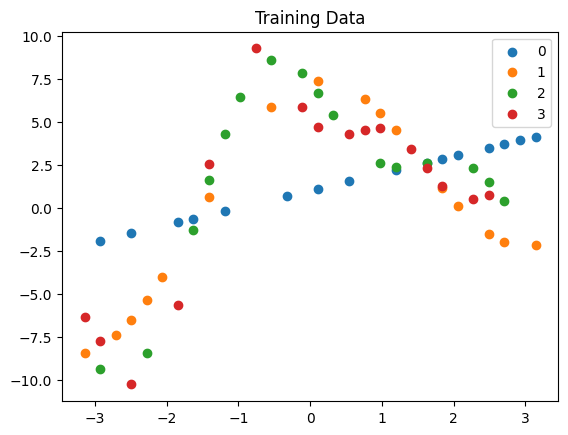

In [7]:
n_modes = 4

X_train, Y_train, Y_train_full = nice_periodic_train_data(2, n_modes, 1234, full=True)

X_plot, _, Y_plot = nice_periodic_train_data(100, n_modes, 1234, full=True, shuffle=False)

for i,m in enumerate(range(n_modes)):
    plt.scatter(X_train.detach(), Y_train.detach()[:,i], label=m)
plt.legend(loc="upper right")
plt.title("Training Data")

## 1. Single Modality Model

In [8]:
pyro.set_rng_seed(2024)
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)

In [9]:
Y_train_single = Y_train[:,-1:]
Y_present_single = Y_train_single.isfinite().squeeze(-1)
Y_train_single = Y_train_single[Y_present_single,:]
X_train_single = X_train[Y_present_single,:]


In [10]:

#single = TIBNN2.from_data(X_train_single, Y_train_single, width = width, depth = depth, prior_variance = prior_variance, fixed_scale = fixed_scale)
single = RegBNN.from_data(X_train_single, Y_train_single, hidden_widths=hidden_widths, prior_variance = prior_variance, activation = activation)

#guide_single = TIBNN2Guide(single, init_style = "random", family = family)
#guide_single = pyro.infer.autoguide.AutoDelta(single.no_missing())
#svi_single = pyro.infer.SVI(single.no_missing(), guide_single, adam, elbo)
guide_single = RegBNNGuide(single, missingdata = missingdata)
svi_single = pyro.infer.SVI(single, guide_single, adam, elbo)

with param_store.scope() as single_params:
    start_single = timer()
    losses = do_svi(svi_single, check_interval = 500)
    stop_single = timer()

# nuts_single = NUTS(single.no_missing(), jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# # Sample
# mcmc_single = MCMC(nuts_single, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
# start_single = timer()
# mcmc_single.run(X_train = X_train, Y_train = Y_train[:,-1:])
# stop_single = timer()

print("Elapsed time: {:.1f}s".format(stop_single - start_single))

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")
Step 500, Elbo loss: 44498.3 +/- 23248.4 (slope = -78090.855 +/- 1734.920 loss/k-iter, p-value = 0.000) 
Step 1000, Elbo loss: 22212.6 +/- 7692.4 (slope = -26500.669 +/- 226.377 loss/k-iter, p-value = 0.000) 
Step 1500, Elbo loss: 12152.9 +/- 4249.6 (slope = -14624.944 +/- 138.442 loss/k-iter, p-value = 0.000) 
Step 2000, Elbo loss: 6630.4 +/- 2314.4 (slope = -7945.149 +/- 90.627 loss/k-iter, p-value = 0.000) 
Step 2500, Elbo loss: 3628.7 +/- 1253.9 (slope = -4279.996 +/- 64.028 loss/k-iter, p-value = 0.000) 
Step 3000, Elbo loss: 2043.3 +/- 656.4 (slope = -2217.744 +/- 44.065 loss/k-iter, p-value = 0.000) 
Step 3500, Elbo loss: 1238.0 +/- 338.8 (slope = -1118.995 +/- 31.401 loss/k-iter, p-value = 0.000) 
Step 4000, Elbo loss: 830.4 +/- 174.2 (slope = -531.537 +/- 25.490 loss/k-iter, p-value = 0.000) 
Step

Elapsed time: 302.1s


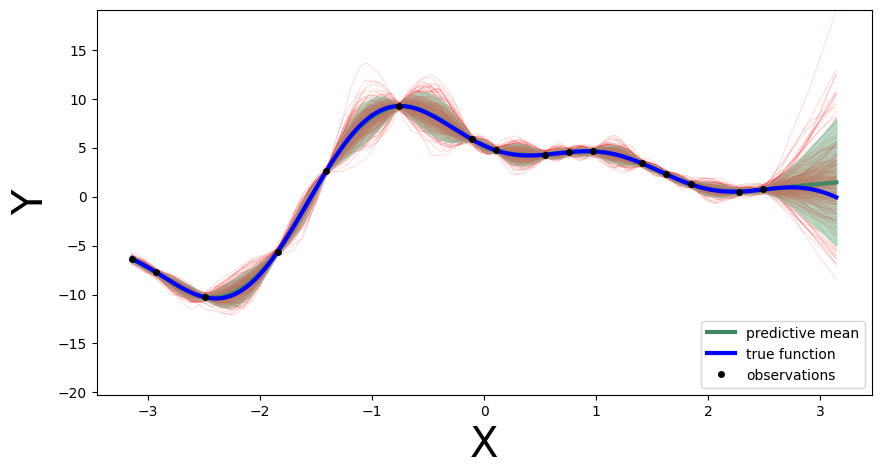

In [11]:
with param_store.scope(single_params):
    plot_predictions_svi(single, guide_single, X_plot, Y_plot[:,-1:], X_train_single, Y_train_single, num_samples = 500)
#plot_predictions_mcmc(single, mcmc_single, X_plot, Y_plot[:,-1:], X_train_single, Y_train_single, pred_site = "mu_pred")

## 2. Joint output Model

In [12]:
multiple = RegBNN.from_data(X_train, Y_train, hidden_widths = hidden_widths, prior_variance = prior_variance, activation = activation)

guide_multiple = RegBNNGuide(multiple, missingdata = missingdata)
svi_multiple = pyro.infer.SVI(multiple, guide_multiple, adam, elbo)
#guide_multiple = pyro.infer.autoguide.AutoDelta(multiple.no_missing())
#svi_multiple = pyro.infer.SVI(multiple.no_missing(), guide_multiple, adam, elbo)


In [13]:

with param_store.scope() as multiple_params:
    start_multiple = timer()
    losses = do_svi(svi_multiple, check_interval = 500)
    end_multiple = timer()

# nuts_multiple = NUTS(multiple.no_missing(), jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# # Sample
# mcmc_multiple = MCMC(nuts_multiple, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
# start_multiple = timer()
# mcmc_multiple.run(X_train = X_train, Y_train = Y_train[:,-1:])
# stop_multiple = timer()
print("Elapsed time: {:.1f}s".format(end_multiple - start_multiple))

Step 500, Elbo loss: 44064.3 +/- 22647.9 (slope = -76052.052 +/- 1697.901 loss/k-iter, p-value = 0.000) 
Step 1000, Elbo loss: 22178.0 +/- 7598.4 (slope = -26176.907 +/- 223.574 loss/k-iter, p-value = 0.000) 
Step 1500, Elbo loss: 12213.4 +/- 4231.1 (slope = -14574.222 +/- 126.298 loss/k-iter, p-value = 0.000) 
Step 2000, Elbo loss: 6707.0 +/- 2309.7 (slope = -7923.080 +/- 94.588 loss/k-iter, p-value = 0.000) 
Step 2500, Elbo loss: 3705.7 +/- 1256.8 (slope = -4290.389 +/- 63.960 loss/k-iter, p-value = 0.000) 
Step 3000, Elbo loss: 2110.3 +/- 658.2 (slope = -2223.775 +/- 44.161 loss/k-iter, p-value = 0.000) 
Step 3500, Elbo loss: 1291.9 +/- 351.2 (slope = -1154.158 +/- 34.098 loss/k-iter, p-value = 0.000) 
Step 4000, Elbo loss: 880.8 +/- 187.7 (slope = -572.855 +/- 27.438 loss/k-iter, p-value = 0.000) 
Step 4500, Elbo loss: 679.5 +/- 103.2 (slope = -258.883 +/- 22.027 loss/k-iter, p-value = 0.000) 
Step 5000, Elbo loss: 581.9 +/- 80.0 (slope = -132.092 +/- 21.809 loss/k-iter, p-value = 

Elapsed time: 796.5s


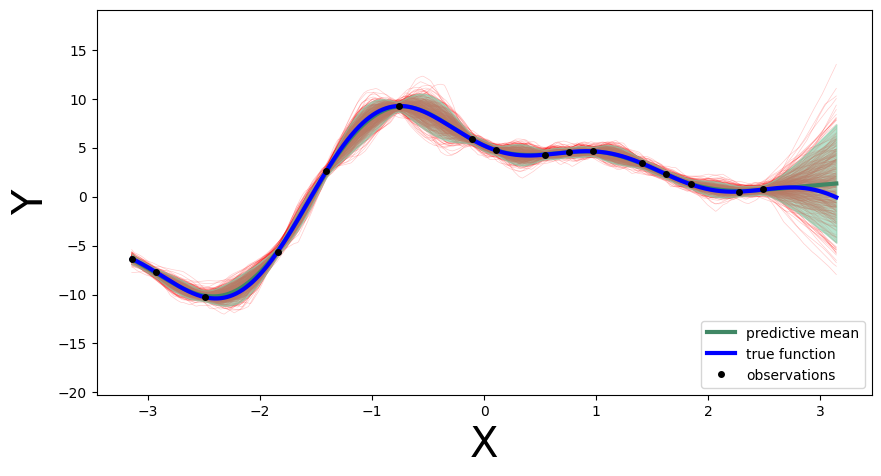

In [14]:
with param_store.scope(multiple_params):
    plot_predictions_svi(multiple, guide_multiple, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:], num_samples = 500)

In [15]:
def cov2cor(Sigma: torch.Tensor) -> torch.Tensor:
    invsds = 1.0 / Sigma.diagonal(dim1=-2, dim2=-1).sqrt()
    return Sigma * invsds.unsqueeze(-1) * invsds.unsqueeze(-2)

with param_store.scope(multiple_params):
    precision = Predictive(multiple, guide = guide_multiple, return_sites=["precision"], num_samples=500).get_samples()['precision']
    print(torch.linalg.inv(precision).mean(dim=[0,1]))
    print(cov2cor(torch.linalg.inv(precision)).mean(dim=[0,1]))


tensor([[ 2.4280e-04,  9.1745e-06, -8.6407e-06,  1.7637e-07],
        [ 9.1745e-06,  4.7812e-04,  7.8842e-05,  1.9780e-04],
        [-8.6407e-06,  7.8842e-05,  1.2312e-03,  4.9718e-04],
        [ 1.7637e-07,  1.9780e-04,  4.9718e-04,  2.5356e-03]])
tensor([[ 1.0000e+00,  2.2288e-02, -1.6327e-02,  1.4211e-04],
        [ 2.2288e-02,  1.0000e+00,  1.0046e-01,  1.7391e-01],
        [-1.6327e-02,  1.0046e-01,  1.0000e+00,  2.8409e-01],
        [ 1.4211e-04,  1.7391e-01,  2.8409e-01,  1.0000e+00]])


In [28]:
with param_store.scope(multiple_params):
    ll_act = Predictive(multiple, guide = guide_multiple, return_sites=["last/activation"], num_samples=500).get_samples()['last/activation']


In [31]:
X_train

tensor([[ 2.9249],
        [-2.0583],
        [-0.9750],
        [-0.7583],
        [ 2.0583],
        [-1.1916],
        [ 0.5417],
        [-0.5417],
        [-3.1416],
        [ 2.2749],
        [ 2.7083],
        [-2.4916],
        [ 1.6250],
        [-1.4083],
        [ 0.1083],
        [-0.3250],
        [-2.7083],
        [ 0.3250],
        [ 1.4083],
        [ 3.1416],
        [-1.6250],
        [-1.8416],
        [-2.2749],
        [ 0.7583],
        [-0.1083],
        [ 1.1916],
        [ 1.8416],
        [-2.9249],
        [ 0.9750],
        [ 2.4916]])

## 3. Separate Model with Predictors

In [ ]:
layered = LayeredTIBNN2.from_data(X_train, X_train_single, Y_train[:,:-1], Y_train_single, width = width, depth = depth, prior_variance = prior_variance, fixed_scale = fixed_scale)

guide_layered = LayeredTIBNN2Guide(layered, init_style = "prior", family = family)

svi_layered = pyro.infer.SVI(layered, guide_layered, adam, elbo)

with param_store.scope() as multiple_params:
    start_layered = timer()
    losses = do_svi(svi_layered, check_interval = 500)
    end_layered = timer()

# nuts_layered = NUTS(layered.no_missing(), jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# # Sample
# mcmc_layered = MCMC(nuts_layered, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
# start_layered = timer()
# mcmc_layered.run(X1_train = X_train, X2_train = X_train, Y1_train = Y_train[:,:-1], Y2_train = Y_train[:,-1:])
# stop_layered = timer()
print("Elapsed time: {:.1f}s".format(end_layered - start_layered))

In [ ]:
plot_predictions_svi(layered, guide_layered, X_plot, Y_plot[:,-1:], X_train_single, Y_train_single, pred_site="main/mu_pred", num_samples = 500)

# 4. Removing one useful data source

In [ ]:
select_3 = [0,1,3]
X_train_3, Y_train_3, Y_train_full_3 = X_train, Y_train[:,select_3], Y_train_full[:,select_3]
X_plot_3, Y_plot_3 = X_plot, Y_plot[:,select_3]

## 4a. Joint output model

In [ ]:
multiple_3 = TIBNN.from_data(X_train_3, Y_train_3, width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_multiple_3 = NUTS(multiple_3, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_multiple_3 = MCMC(nuts_multiple_3, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
start_multiple_3 = timer()
mcmc_multiple_3.run(X_train_3, Y_train_3)
stop_multiple_3 = timer()
print("Elapsed time: {:.1f}s".format(stop_multiple_3 - start_multiple_3))

In [ ]:
plot_predictions(multiple_3, mcmc_multiple_3, X_plot_3, Y_plot_3[:,-1:], X_train_3, Y_train_3[:,-1:])

## 4b. Layered model

In [ ]:
layered_3 = LayeredTIBNN.from_data(X_train_3, Y_train_3[:,:-1], Y_train_3[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_layered_3 = NUTS(layered_3, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_layered_3 = MCMC(nuts_layered_3, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = 2, mp_context = "spawn")
start_layered_3 = timer()
mcmc_layered_3.run(X_train_3, Y_train_3[:,:-1], Y_train_3[:,-1:])
stop_layered_3 = timer()
print("Elapsed time: {:.1f}s".format(stop_layered_3 - start_layered_3))

In [ ]:
plot_predictions(layered_3, mcmc_layered_3, X_plot_3, Y_plot_3[:,-1:], X_train_3, Y_train_3[:,-1:], pred_site="second/mu")

# 5. Extra garbage data source

In [ ]:
torch.manual_seed(2024)
Y_garbage = 3 * torch.randn_like(X_train)
Y_plot_garbage = 3 * torch.randn_like(X_plot)

X_train_5 = X_train
Y_train_5 = torch.cat([Y_garbage, Y_train], dim = -1)
Y_train_full_5 = torch.cat([Y_garbage, Y_train_full], dim = -1)
X_plot_5 = X_plot
Y_plot_5 = torch.cat([Y_plot_garbage, Y_plot], dim = -1)

## 5a. Joint output model

In [ ]:
multiple_5 = TIBNN.from_data(X_train_5, Y_train_5, width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_multiple_5 = NUTS(multiple_5, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_multiple_5 = MCMC(nuts_multiple_5, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
start_multiple_5 = timer()
mcmc_multiple_5.run(X_train_5, Y_train_5)
stop_multiple_5 = timer()
print("Elapsed time: {:.1f}s".format(stop_multiple_5 - start_multiple_5))

In [ ]:
plot_predictions(multiple_5, mcmc_multiple_5, X_plot_5, Y_plot_5[:,-1:], X_train_5, Y_train_5[:,-1:])

## 5b. Layered model

In [ ]:
layered_5 = LayeredTIBNN.from_data(X_train_5, Y_train_5[:,:-1], Y_train_5[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_layered_5 = NUTS(layered_5, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_layered_5 = MCMC(nuts_layered_5, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = 2, mp_context = "spawn")
start_layered_5 = timer()
mcmc_layered_5.run(X_train_5, Y_train_5[:,:-1], Y_train_5[:,-1:])
stop_layered_5 = timer()
print("Elapsed time: {:.1f}s".format(stop_layered_5 - start_layered_5))

In [ ]:
plot_predictions(layered_5, mcmc_layered_5, X_plot_5, Y_plot_5[:,-1:], X_train_5, Y_train_5[:,-1:], pred_site="second/mu")